# Criticality Metrics and Responsibility-Sensitive Safety (RSS)

**Module 04 · SOTIF (ISO 21448)** · Notebook 5 of 5

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/milinpatel07/Autonomous-Driving_AI-Safety-and-Security/blob/main/04_SOTIF_ISO21448/05_criticality_metrics_and_rss.ipynb)

| Level | Prerequisites | Standards |
|---|---|---|
| Intermediate | [01 SOTIF fundamentals](01_sotif_fundamentals.ipynb), [04 Simulation-based validation](04_simulation_based_validation.ipynb); kinematics (constant acceleration) | ISO 21448:2022, IEEE 2846-2022, UL 4600 (3rd ed., 2023), ISO 34502:2022 |

**Author:** Milin Patel · Hochschule Kempten · MIT Licence

## Learning objectives

By the end of this notebook you will be able to:

1. Define and compute the surrogate safety (criticality) metrics **TTC, THW, DRAC, required deceleration and PET**, and state the assumptions behind each.
2. Recognise the **failure modes** of these metrics (e.g. TTC is infinite when the vehicles are not closing; longitudinal metrics are blind to lateral conflicts).
3. **Derive** the RSS minimum safe longitudinal distance from its worst-case assumptions and implement it exactly as in the paper.
4. Explain RSS's notions of **dangerous situation, proper response and responsibility**, including the lateral case.
5. Quantify the **sensitivity** of the RSS envelope to its parameters and the resulting **safety–usefulness trade-off**.
6. Simulate a **cut-in** and compare an RSS-compliant controller with a naive one using metrics over time.
7. Position such safety envelopes in **ISO 21448**, **IEEE 2846-2022** and **UL 4600** arguments, and state their limitations.

## 1. Why criticality metrics?

Crashes are, fortunately, rare events. Validating an automated driving system (ADS) only by counting crashes would require an impractical amount of driving (see [Module 06, Notebook 07](../06_AI_Safety_ISO_PAS_8800/08_statistical_safety_validation.ipynb)). Traffic-safety research has therefore long used **surrogate safety measures**: quantities observable in *every* encounter that indicate how close it came to a collision. Hayward (1972) proposed the time remaining until two vehicles would collide if they kept their course and speed, the **time-to-collision (TTC)**, as a unit of a "scale of danger"; Allen, Shin and Cooper (1978) introduced **post-encroachment time (PET)** for crossing conflicts. Reviews by Mahmud et al. (2017) and Westhofen et al. (2023) catalogue dozens of such metrics and analyse their suitability for automated driving.

In the SOTIF context, criticality metrics serve at least four purposes:

| Use | Example |
|---|---|
| **Scenario evaluation** in simulation or on proving grounds | "minimum TTC in this cut-in run was 0.9 s" |
| **Acceptance criteria and validation targets** | "TTC < 1.0 s in fewer than X per 10⁶ km" |
| **Identification of hazardous scenarios and triggering conditions** | search parameter spaces for low-TTC regions ([Notebook 04](04_simulation_based_validation.ipynb)) |
| **Runtime monitoring and safety envelopes** | a monitor overrides the planner if the RSS distance is violated |

The last row is qualitatively different: a **formal safety envelope** such as RSS does not just *measure* criticality after the fact; it specifies, from explicit assumptions, which states are acceptable and how the vehicle must respond when they are not.

In [1]:
# Setup: standard scientific Python only
import math
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

T0 = time.time()
rng = np.random.default_rng(42)
OI = {"orange": "#E69F00", "skyblue": "#56B4E9", "green": "#009E73", "yellow": "#F0E442",
      "blue": "#0072B2", "vermillion": "#D55E00", "purple": "#CC79A7", "black": "#000000"}
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "axes.titleweight": "bold"})
KMH = 1 / 3.6
print("Setup complete.")

Setup complete.


## 2. Surrogate safety metrics

Consider a following vehicle (subscript $f$, often the ego vehicle) behind a leading vehicle ($l$) in the same lane, with bumper-to-bumper gap $g$, speeds $v_f, v_l$ and the lead's current deceleration $b_l \ge 0$.

| Metric | Definition | Key assumption | Typical failure mode |
|---|---|---|---|
| **Time-to-collision** | $\text{TTC} = \dfrac{g}{v_f - v_l}$ if $v_f > v_l$, else $\infty$ | both speeds stay constant | infinite at any gap when not closing; ignores the lead's braking |
| **Time headway / time gap** | $\text{THW} = \dfrac{g}{v_f}$ | none (state only) | ignores relative speed; says nothing at standstill |
| **Deceleration rate to avoid a crash** | $\text{DRAC} = \dfrac{(v_f - v_l)^2}{2g}$ if closing, else $0$ | lead keeps a constant speed | under-estimates the need when the lead brakes |
| **Required deceleration** | smallest constant $a$ for which the follower, braking at $a$, does not hit a lead braking at $b_l$ to standstill | lead's current deceleration persists | needs $b_l$, which is noisy to estimate |
| **Post-encroachment time** | $\text{PET} = t_{\text{2, enters}} - t_{\text{1, leaves}}$ for a conflict area | paths cross a defined area | only defined *after* the encounter; no severity |

Strictly, *time headway* is measured front-to-front; with a bumper-to-bumper gap the quantity is often called the *time gap*. We use the gap-based form, as in `avsafety.sotif.time_headway`.

The same functions are available in the repository's tested toolkit as `avsafety.sotif.time_to_collision`, `time_headway`, `drac` and `rss_safe_longitudinal_distance` (see repo `avsafety/`). The notebook keeps its own copies so that it runs stand-alone in Colab, and cross-checks them against the toolkit when it is available.

In [2]:
def time_to_collision(gap_m, v_follow, v_lead):
    # TTC [s] for a follower approaching a leader on the same path (inf if not closing)
    closing = v_follow - v_lead
    if gap_m <= 0:
        return 0.0
    return gap_m / closing if closing > 0 else math.inf


def time_headway(gap_m, v_follow):
    # THW = gap / follower speed [s]
    return gap_m / v_follow if v_follow > 0 else math.inf


def drac(gap_m, v_follow, v_lead):
    # Deceleration rate to avoid crash, (v_f - v_l)^2 / (2 gap) [m/s^2] (0 if not closing)
    closing = v_follow - v_lead
    if closing <= 0:
        return 0.0
    if gap_m <= 0:
        return math.inf
    return closing ** 2 / (2 * gap_m)


def required_deceleration(gap_m, v_follow, v_lead, b_lead=0.0, a_limit=15.0, n=400):
    # Smallest constant follower deceleration [m/s^2] avoiding a collision with a lead that brakes at b_lead
    # until standstill. Evaluated by bisection on the exact piecewise kinematics; inf if above a_limit.
    if gap_m <= 0:
        return math.inf

    def min_gap(a):
        t_end = max(v_follow / a, v_lead / b_lead if b_lead > 0 else v_follow / a)
        t = np.linspace(0.0, t_end, n)
        x_f = np.where(t < v_follow / a, v_follow * t - 0.5 * a * t**2, v_follow**2 / (2 * a))
        if b_lead > 0:
            x_l = np.where(t < v_lead / b_lead, v_lead * t - 0.5 * b_lead * t**2, v_lead**2 / (2 * b_lead))
        else:
            x_l = v_lead * t
        return np.min(gap_m + x_l - x_f)

    if min_gap(1e-3) >= 0:
        return 0.0
    if min_gap(a_limit) < 0:
        return math.inf
    lo, hi = 1e-3, a_limit
    for _ in range(40):
        mid = 0.5 * (lo + hi)
        lo, hi = (lo, mid) if min_gap(mid) >= 0 else (mid, hi)
    return hi


# sanity checks against closed forms
assert abs(required_deceleration(50.0, 20.0, 0.0) - 20.0**2 / (2 * 50.0)) < 1e-3         # static obstacle
assert abs(required_deceleration(30.0, 25.0, 15.0) - drac(30.0, 25.0, 15.0)) < 1e-3       # constant-speed lead
print("Metric functions defined; closed-form sanity checks passed.")

Metric functions defined; closed-form sanity checks passed.


### 2.1 Five situations, five metrics

The table evaluates the metrics on five hand-picked situations. The thresholds used to *flag* a situation (TTC < 3 s, THW < 1 s, DRAC or required deceleration > 3 m/s²) are illustrative round numbers, not normative values; published thresholds vary by study and context (Mahmud et al., 2017).

> **Illustrative data:** values below are synthetic, chosen for teaching; they are not measurements.

In [3]:
situations = pd.DataFrame([
    # name,                                   gap,  v_f,       v_l,       b_l, lateral?
    ("A: same speed, very short gap",          8.0, 30.0,      30.0,      0.0, False),
    ("B: slow closing, long gap",             60.0, 30.0,      28.0,      0.0, False),
    ("C: fast closing, moderate gap",         40.0, 30.0,      15.0,      0.0, False),
    ("D: lead brakes hard, equal speed",      25.0, 25.0,      25.0,      7.0, False),
    ("E: adjacent car drifting into lane",    0.0,  25.0,      25.0,      0.0, True),
], columns=["situation", "gap_m", "v_f", "v_l", "b_l", "lateral"]).set_index("situation")


def evaluate(row):
    if row.lateral:      # side-by-side: there is no longitudinal gap to the other car at all
        return pd.Series({"TTC [s]": np.nan, "THW [s]": np.nan, "DRAC [m/s2]": np.nan,
                          "req. decel [m/s2]": np.nan})
    return pd.Series({"TTC [s]": time_to_collision(row.gap_m, row.v_f, row.v_l),
                      "THW [s]": time_headway(row.gap_m, row.v_f),
                      "DRAC [m/s2]": drac(row.gap_m, row.v_f, row.v_l),
                      "req. decel [m/s2]": required_deceleration(row.gap_m, row.v_f, row.v_l, row.b_l)})


table = situations.apply(evaluate, axis=1)
flags = pd.DataFrame({"TTC flags": table["TTC [s]"] < 3.0, "THW flags": table["THW [s]"] < 1.0,
                      "DRAC flags": table["DRAC [m/s2]"] > 3.0,
                      "req. decel flags": table["req. decel [m/s2]"] > 3.0})
print(pd.concat([table.round(2), flags], axis=1).to_string())
print("\nText summary:")
for s in table.index:
    raised = [c.replace(" flags", "") for c in flags.columns if flags.loc[s, c]]
    print(f"  {s}: flagged by {', '.join(raised) if raised else 'none of the longitudinal metrics'}")

                                    TTC [s]  THW [s]  DRAC [m/s2]  req. decel [m/s2]  TTC flags  THW flags  DRAC flags  req. decel flags
situation                                                                                                                               
A: same speed, very short gap           inf     0.27         0.00               0.00      False       True       False             False
B: slow closing, long gap             30.00     2.00         0.03               0.03      False      False       False             False
C: fast closing, moderate gap          2.67     1.33         2.81               2.81       True      False       False             False
D: lead brakes hard, equal speed        inf     1.00         0.00               4.49      False      False       False              True
E: adjacent car drifting into lane      NaN      NaN          NaN                NaN      False      False       False             False

Text summary:
  A: same speed, very shor

Observations, all visible in the table:

- **A** is a tailgating situation at 108 km/h: no metric based on *relative* speed (TTC, DRAC) reacts, because the vehicles are not closing. Only THW notices, and only the required deceleration *if* the lead starts braking.
- **D** has an *infinite* TTC and zero DRAC at the moment the lead starts braking hard, although a large deceleration is needed: the constant-speed assumption hides the threat until the speeds have diverged.
- **E** (a lateral conflict) is invisible to all longitudinal metrics. Lateral or two-dimensional extensions exist (Westhofen et al., 2023), and RSS treats the lateral direction explicitly (Section 4.4).

No single surrogate metric is sufficient; each encodes a prediction model of the other road user, and the metric is only as good as that model.

### 2.2 Metrics over time when the lead brakes

The time series below makes situation D dynamic: both vehicles travel at 25 m/s with a 25 m gap; at $t = 1$ s the lead brakes at 7 m/s² to a standstill, and the follower reacts after 1.0 s with 5 m/s². We compute each metric at every instant from the current state, as an online monitor would.

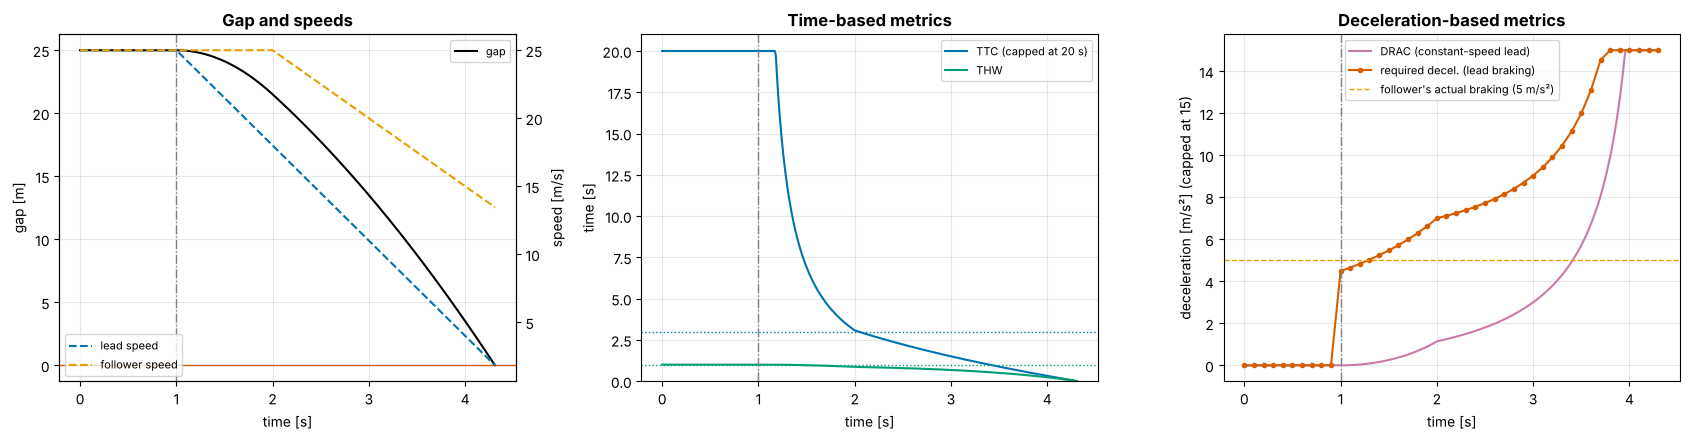

Lead starts braking at t = 1.0 s. Required deceleration first exceeds the follower's 5 m/s² at t = 1.3 s; TTC first drops below 3 s at t = 2.04 s; DRAC first exceeds 5 m/s² at t = 3.41 s.
Text summary: the follower collides with the lead at t = 4.31 s; the constant-speed metrics react 0.74 s (TTC) and 2.11 s (DRAC) later than the required deceleration.


In [4]:
def two_car_braking(gap0=25.0, v0=25.0, t_brake=1.0, b_lead=7.0, reaction=1.0, b_follow=5.0, dt=0.01, T=7.0):
    t = np.arange(0.0, T, dt)
    v_l = np.where(t < t_brake, v0, np.maximum(v0 - b_lead * (t - t_brake), 0.0))
    v_f = np.where(t < t_brake + reaction, v0, np.maximum(v0 - b_follow * (t - t_brake - reaction), 0.0))
    x_l = gap0 + np.concatenate([[0.0], np.cumsum(0.5 * (v_l[1:] + v_l[:-1]) * dt)])
    x_f = np.concatenate([[0.0], np.cumsum(0.5 * (v_f[1:] + v_f[:-1]) * dt)])
    gap = x_l - x_f
    b_now = np.where((t >= t_brake) & (v_l > 0), b_lead, 0.0)
    out = pd.DataFrame({"t": t, "gap": gap, "v_f": v_f, "v_l": v_l})
    out["TTC"] = [time_to_collision(g, a, b) for g, a, b in zip(gap, v_f, v_l)]
    out["THW"] = [time_headway(g, a) for g, a in zip(gap, v_f)]
    out["DRAC"] = [drac(g, a, b) for g, a, b in zip(gap, v_f, v_l)]
    idx = np.arange(0, len(t), 10)                       # required deceleration every 0.1 s (bisection is costlier)
    out["req_decel"] = np.nan
    out.loc[idx, "req_decel"] = [required_deceleration(gap[i], v_f[i], v_l[i], b_now[i]) if gap[i] > 0 else np.inf
                                 for i in idx]
    return out


ts = two_car_braking()
end = ts["gap"].le(0).idxmax() if ts["gap"].le(0).any() else len(ts) - 1
ts = ts.iloc[:end + 1]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].plot(ts.t, ts.gap, color=OI["black"], label="gap"); axes[0].axhline(0, color=OI["vermillion"], lw=1)
axes[0].legend(loc="upper right", fontsize=8)
axes[0].set(title="Gap and speeds", xlabel="time [s]", ylabel="gap [m]")
ax2 = axes[0].twinx(); ax2.plot(ts.t, ts.v_l, color=OI["blue"], ls="--", label="lead speed")
ax2.plot(ts.t, ts.v_f, color=OI["orange"], ls="--", label="follower speed"); ax2.set_ylabel("speed [m/s]")
ax2.legend(loc="lower left", fontsize=8); ax2.grid(False)
axes[1].plot(ts.t, np.minimum(ts.TTC, 20), color=OI["blue"], label="TTC (capped at 20 s)")
axes[1].plot(ts.t, ts.THW, color=OI["green"], label="THW")
axes[1].axhline(3.0, color=OI["blue"], ls=":", lw=1); axes[1].axhline(1.0, color=OI["green"], ls=":", lw=1)
axes[1].set(title="Time-based metrics", xlabel="time [s]", ylabel="time [s]", ylim=(0, 21)); axes[1].legend(fontsize=8)
rd = ts.dropna(subset=["req_decel"])
axes[2].plot(ts.t, np.minimum(ts.DRAC, 15), color=OI["purple"], label="DRAC (constant-speed lead)")
axes[2].plot(rd.t, np.minimum(rd.req_decel, 15), "o-", ms=3, color=OI["vermillion"], label="required decel. (lead braking)")
axes[2].axhline(5.0, color=OI["orange"], ls="--", lw=1, label="follower's actual braking (5 m/s²)")
axes[2].set(title="Deceleration-based metrics", xlabel="time [s]", ylabel="deceleration [m/s²] (capped at 15)")
axes[2].legend(fontsize=8)
for a in axes: a.axvline(1.0, color="grey", lw=1, ls="-.")
plt.tight_layout(); plt.show()

t_req = rd.loc[rd.req_decel > 5.0, "t"].min()
t_ttc = ts.loc[ts.TTC < 3.0, "t"].min()
t_drac = ts.loc[ts.DRAC > 5.0, "t"].min()
collided = bool(ts["gap"].iloc[-1] <= 0)
print(f"Lead starts braking at t = 1.0 s. Required deceleration first exceeds the follower's 5 m/s² at t = {t_req:.1f} s; "
      f"TTC first drops below 3 s at t = {t_ttc:.2f} s; DRAC first exceeds 5 m/s² at t = {t_drac:.2f} s.")
print(f"Text summary: the follower {'collides with' if collided else 'stops behind'} the lead "
      f"{'at t = %.2f s' % ts.t.iloc[-1] if collided else ''}; the constant-speed metrics react "
      f"{t_ttc - t_req:.2f} s (TTC) and {t_drac - t_req:.2f} s (DRAC) later than the required deceleration.")

### 2.3 Crossing conflicts and PET

For crossing paths (a pedestrian on a zebra crossing, a turning vehicle) there is no common longitudinal axis. **PET** measures the time between the first road user *leaving* a conflict area and the second *entering* it. Small PET means a near miss, but PET is only known after the event and says nothing about speed (severity). Below, a car at 50 km/h passes a crossing pedestrian in three variants.

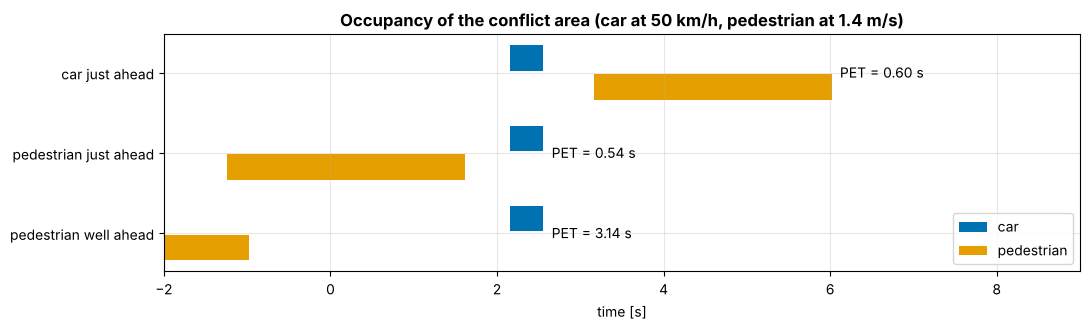

                      first through  PET [s]  collision
variant                                                
pedestrian well ahead    pedestrian     3.14      False
pedestrian just ahead    pedestrian     0.54      False
car just ahead                  car     0.60      False

Text summary: PET ranges from 0.5 s to 3.1 s with 0 collision(s); the smallest PET marks the nearest miss. A same-path TTC is undefined here because the paths cross instead of following each other.


In [5]:
def occupancy_interval(pos_entry, length, speed):
    # time interval [s] during which an object moving at constant speed occupies an area of given length
    return pos_entry / speed, (pos_entry + length) / speed


def pet(first, second):
    # PET = second entry - first exit (negative would mean simultaneous occupancy, i.e. a collision)
    return second[0] - first[1]


CAR_LEN, PED_LEN = 4.5, 0.5            # occupied lengths along the respective paths [m]
LANE_W = 3.5                           # conflict area: width of the car's lane (ped path) x pedestrian corridor (car path)
v_car = 50 * KMH
variants = {"pedestrian well ahead": 6.0, "pedestrian just ahead": 3.4, "car just ahead": -1.0}
fig, ax = plt.subplots(figsize=(11, 3.4))
rows = []
for k, (name, ped_lead) in enumerate(variants.items()):
    car_iv = occupancy_interval(30.0, 1.0 + CAR_LEN, v_car)             # car 30 m before the 1 m-wide crossing corridor
    t_ped_entry = car_iv[0] - ped_lead
    ped_iv = (t_ped_entry, t_ped_entry + (LANE_W + PED_LEN) / 1.4)       # pedestrian at 1.4 m/s across the lane
    first, second = (ped_iv, car_iv) if ped_iv[0] < car_iv[0] else (car_iv, ped_iv)
    p = pet(first, second)
    rows.append({"variant": name, "first through": "pedestrian" if first is ped_iv else "car", "PET [s]": p,
                 "collision": p < 0})
    for iv, c, lab in [(car_iv, OI["blue"], "car"), (ped_iv, OI["orange"], "pedestrian")]:
        ax.barh(k + (0.18 if lab == "car" else -0.18), iv[1] - iv[0], left=iv[0], height=0.32, color=c,
                label=lab if k == 0 else None)
    ax.annotate(f"PET = {p:.2f} s", (max(car_iv[1], ped_iv[1]) + 0.1, k), va="center")
ax.set_yticks(range(len(variants))); ax.set_yticklabels(list(variants))
ax.set(title="Occupancy of the conflict area (car at 50 km/h, pedestrian at 1.4 m/s)", xlabel="time [s]", xlim=(-2, 9))
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()
pet_df = pd.DataFrame(rows).set_index("variant")
print(pet_df.round(2).to_string())
print(f"\nText summary: PET ranges from {pet_df['PET [s]'].min():.1f} s to {pet_df['PET [s]'].max():.1f} s with "
      f"{int(pet_df['collision'].sum())} collision(s); the smallest PET marks the nearest miss. A same-path TTC is "
      f"undefined here because the paths cross instead of following each other.")

## 3. Responsibility-Sensitive Safety: the idea

Shalev-Shwartz, Shammah and Shashua (2017) proposed RSS as "a rigorous mathematical model formalizing an interpretation of the Duty of Care law" (arXiv:1708.06374, v6, Section 3). It is built from five "common sense" rules (ibid.):

1. Do not hit someone from behind.
2. Do not cut-in recklessly.
3. Right-of-way is given, not taken.
4. Be careful of areas with limited visibility.
5. If you can avoid an accident without causing another one, you must do it.

RSS turns these into **definitions** (safe distance, dangerous situation, proper response, responsibility) that depend on a small set of **parameters**, which encode *assumptions about the worst-case behaviour of other road users*. The central result is inductive: if every agent responds properly to dangerous situations, no collisions occur (Lemma 5 for multi-lane roads); and if a collision does occur, at least one agent did not respond properly and is **responsible** (Section 3.10, without occlusions).

Note what this does and does not claim. RSS is a model of *not causing* collisions under stated assumptions; it is not a guarantee that the ego vehicle will never be in a collision.

## 4. The longitudinal safe distance

### 4.1 Derivation

**Definition 1** (paraphrased from the paper): the longitudinal distance between a rear car $c_r$ and a front car $c_f$ driving in the same direction is *safe* with respect to a response time $\rho$ if, for any braking of at most $b_{\max}$ by $c_f$, the rear car can accelerate by at most $a_{\max}$ during $\rho$ and then brake by at least $b_{\min}$ to a full stop without colliding. (In the paper: $a_{\max,\text{brake}}$, $a_{\max,\text{accel}}$ and $a_{\min,\text{brake}}$.)

The **worst case** is: the front car brakes as hard as allowed, $b_{\max}$, immediately; the rear car, during its response time, still *accelerates* at $a_{\max}$, then brakes only at the guaranteed minimum $b_{\min}$. Assuming $b_{\min} \le b_{\max}$, once the speeds are equal the front car is always slower, so the gap decreases monotonically until both stand still. It therefore suffices to require a non-negative gap at standstill:

- Distance travelled by the front car until standstill: $\dfrac{v_f^2}{2b_{\max}}$.
- Rear car during the response time: $v_r\rho + \tfrac{1}{2}a_{\max}\rho^2$, reaching speed $v_{r,\rho} = v_r + \rho a_{\max}$.
- Rear car while braking: $\dfrac{v_{r,\rho}^2}{2b_{\min}}$.

Requiring $d_0 + \frac{v_f^2}{2b_{\max}} - \big(v_r\rho + \tfrac{1}{2}a_{\max}\rho^2 + \frac{v_{r,\rho}^2}{2b_{\min}}\big) \ge 0$ gives **Lemma 2**:

$$
d_{\min} = \left[\, v_r\rho + \tfrac{1}{2}a_{\max}\rho^2 + \frac{(v_r + \rho\, a_{\max})^2}{2\, b_{\min}} - \frac{v_f^2}{2\, b_{\max}} \right]_+ ,\qquad [x]_+ := \max\{x, 0\}.
$$

The implementation below is identical to `avsafety.sotif.rss_safe_longitudinal_distance` in the repository toolkit, including its default parameters ($\rho = 0.5$ s, $a_{\max} = 2$, $b_{\min} = 4$, $b_{\max} = 8$ m/s²). These defaults are **illustrative**; the paper argues that such values should be set by regulation (Remark 2), and neither the paper nor this notebook proposes them as normative.

In [6]:
def rss_safe_longitudinal_distance(v_rear, v_front, rho=0.5, a_max_accel=2.0, b_min_brake=4.0, b_max_brake=8.0):
    # Minimal safe longitudinal distance [m], same direction (Shalev-Shwartz et al., 2017, Lemma 2).
    # Accelerations are positive magnitudes [m/s^2]; speeds [m/s]; rho [s].
    if min(rho, a_max_accel, b_min_brake, b_max_brake) < 0 or b_min_brake == 0 or b_max_brake == 0:
        raise ValueError("parameters must be positive")
    v_after = v_rear + rho * a_max_accel
    d = (v_rear * rho + 0.5 * a_max_accel * rho ** 2
         + v_after ** 2 / (2 * b_min_brake) - v_front ** 2 / (2 * b_max_brake))
    return max(d, 0.0)


# The toolkit's unit tests, reproduced here
assert abs(rss_safe_longitudinal_distance(0, 0) - 0.375) < 1e-12
d25 = rss_safe_longitudinal_distance(25, 25)
assert rss_safe_longitudinal_distance(30, 25) > d25 > rss_safe_longitudinal_distance(25, 30)
assert rss_safe_longitudinal_distance(0, 50) == 0.0

# Cross-check against the repository toolkit when the notebook runs inside the repo (skipped in Colab)
try:
    sys.path.insert(0, "..")
    from avsafety import sotif as _tk
    grid = rng.uniform([0, 0, 0.1, 0.5, 1.0, 1.0], [45, 45, 2.0, 4.0, 9.0, 12.0], size=(500, 6))
    diff = max(abs(rss_safe_longitudinal_distance(*g) - _tk.rss_safe_longitudinal_distance(*g)) for g in grid)
    diff_m = max(abs(f(*a) - g(*a)) for f, g, a in
                 [(time_to_collision, _tk.time_to_collision, (30.0, 25.0, 20.0)),
                  (time_headway, _tk.time_headway, (30.0, 25.0)), (drac, _tk.drac, (30.0, 25.0, 20.0))])
    print(f"Cross-check with avsafety.sotif on 500 random parameter sets: max |difference| = {diff:.2e} m; "
          f"TTC/THW/DRAC max difference = {diff_m:.2e}")
except ImportError:
    print("avsafety toolkit not found (e.g. running in Colab): cross-check skipped; the unit tests above passed.")

for v_kmh in (50, 100, 130):
    v = v_kmh * KMH
    d = rss_safe_longitudinal_distance(v, v)
    print(f"Equal speeds {v_kmh:>3} km/h: d_min = {d:6.1f} m  (time gap {d / v:.2f} s)")

Cross-check with avsafety.sotif on 500 random parameter sets: max |difference| = 0.00e+00 m; TTC/THW/DRAC max difference = 0.00e+00
Equal speeds  50 km/h: d_min =   22.8 m  (time gap 1.65 s)
Equal speeds 100 km/h: d_min =   69.4 m  (time gap 2.50 s)
Equal speeds 130 km/h: d_min =  109.0 m  (time gap 3.02 s)


### 4.2 Verifying the worst case numerically

A formula derived from a worst case should be checked against a simulation of that worst case. We start the two cars at exactly $d_{\min}$ and at 90 % of it, apply the worst-case behaviour, and look at the gap.

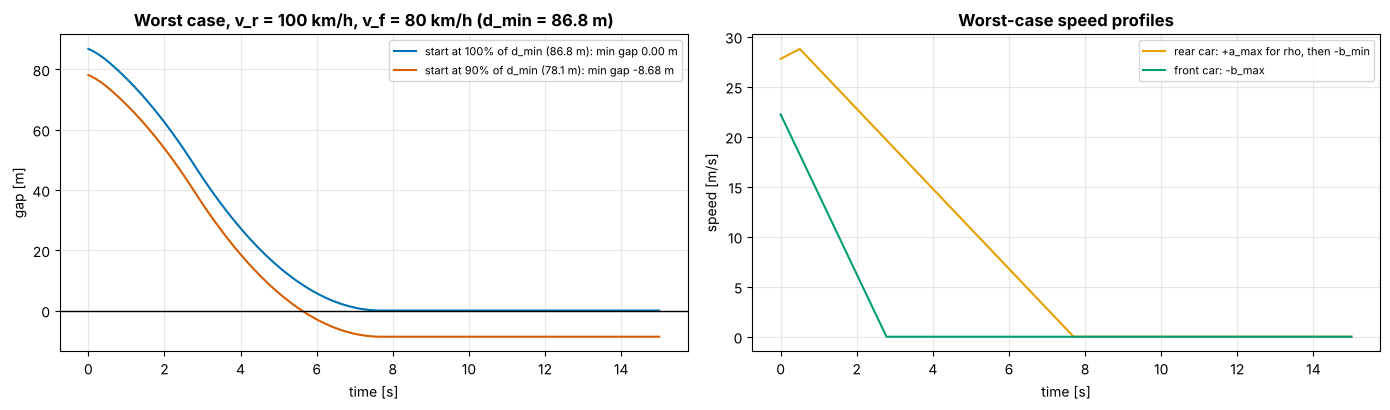

Text summary: starting at d_min the worst-case minimum gap is 0.000 m (zero up to discretisation); starting at 0.9 d_min it is -8.68 m, i.e. a collision.


In [7]:
def worst_case_gap(d0, v_r, v_f, rho=0.5, a_max=2.0, b_min=4.0, b_max=8.0, dt=1e-3, T=15.0):
    t = np.arange(0.0, T, dt)
    v_rear = np.where(t < rho, v_r + a_max * t, np.maximum(v_r + a_max * rho - b_min * (t - rho), 0.0))
    v_front = np.maximum(v_f - b_max * t, 0.0)
    x_r = np.concatenate([[0.0], np.cumsum(0.5 * (v_rear[1:] + v_rear[:-1]) * dt)])
    x_f = d0 + np.concatenate([[0.0], np.cumsum(0.5 * (v_front[1:] + v_front[:-1]) * dt)])
    return t, x_f - x_r, v_rear, v_front


v_r, v_f = 100 * KMH, 80 * KMH
dmin = rss_safe_longitudinal_distance(v_r, v_f)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for frac, c in [(1.0, OI["blue"]), (0.9, OI["vermillion"])]:
    t, gap, vr_, vf_ = worst_case_gap(frac * dmin, v_r, v_f)
    axes[0].plot(t, gap, color=c, label=f"start at {frac:.0%} of d_min ({frac * dmin:.1f} m): min gap {gap.min():.2f} m")
    if frac == 1.0:
        axes[1].plot(t, vr_, color=OI["orange"], label="rear car: +a_max for rho, then -b_min")
        axes[1].plot(t, vf_, color=OI["green"], label="front car: -b_max")
axes[0].axhline(0, color=OI["black"], lw=1)
axes[0].set(title=f"Worst case, v_r = 100 km/h, v_f = 80 km/h (d_min = {dmin:.1f} m)", xlabel="time [s]",
            ylabel="gap [m]"); axes[0].legend(fontsize=8)
axes[1].set(title="Worst-case speed profiles", xlabel="time [s]", ylabel="speed [m/s]"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
g_ok = worst_case_gap(dmin, v_r, v_f)[1].min(); g_bad = worst_case_gap(0.9 * dmin, v_r, v_f)[1].min()
print(f"Text summary: starting at d_min the worst-case minimum gap is {g_ok:.3f} m (zero up to discretisation); "
      f"starting at 0.9 d_min it is {g_bad:.2f} m, i.e. a collision.")

### 4.3 Dangerous situation, proper response, responsibility

- **Dangerous longitudinal situation** (Definition 3): at time $t$ the longitudinal distance is not safe. The *danger threshold* $t_b$ is the start of the current uninterrupted dangerous interval.
- **Longitudinal proper response** (Definition 4, same direction): from $t_b$, the rear car may accelerate by at most $a_{\max}$ during $[t_b, t_b+\rho)$ and must then brake by at least $b_{\min}$ until the situation is safe again; the front car must not brake harder than $b_{\max}$ until then.
- **Responsibility** (Section 3.10): an agent that did not comply with the proper response constraints is responsible for a resulting accident.

The definitions are deliberately one-to-one (the paper's "star-shape" calculations, Remark 1): the ego vehicle evaluates each other agent separately, which keeps the check computationally cheap and analysable.

### 4.4 Lateral safe distance

Because a car's lateral position always fluctuates slightly, RSS uses a *µ-lateral velocity* (Definition 5) and a lateral safety margin $\mu$. For $c_1$ to the left of $c_2$ with lateral velocities $v_1, v_2$ (positive to the right) and $v_{1,\rho} = v_1 + \rho\, a^{\text{lat}}_{\max}$, $v_{2,\rho} = v_2 - \rho\, a^{\text{lat}}_{\max}$, Lemma 4 gives

$$
d^{\text{lat}}_{\min} = \mu + \left[\frac{v_1 + v_{1,\rho}}{2}\rho + \frac{v_{1,\rho}^2}{2\,b^{\text{lat}}_{\min}} - \left(\frac{v_2 + v_{2,\rho}}{2}\rho - \frac{v_{2,\rho}^2}{2\,b^{\text{lat}}_{\min}}\right)\right]_+ .
$$

As printed, this expression is the worst case for cars moving *towards* each other ($v_{1,\rho} \ge 0 \ge v_{2,\rho}$), which is the case we use. A situation is **dangerous** only if it is *both* longitudinally and laterally dangerous (Definition 9). When two cars drive side by side they are already longitudinally unsafe; if the situation becomes dangerous it is because they approach laterally, so the danger threshold is the lateral one and the **lateral** proper response applies (Definition 10). A car that keeps moving laterally into an occupied lane, as in a reckless cut-in, therefore violates its proper response.

The lateral parameters used below ($a^{\text{lat}}_{\max} = 0.2$ m/s², $b^{\text{lat}}_{\min} = 0.8$ m/s², $\mu = 0.5$ m) are illustrative choices for this notebook.

In [8]:
def rss_safe_lateral_distance(v1, v2, rho=0.5, a_lat_max_accel=0.2, b_lat_min_brake=0.8, mu=0.5):
    # Minimal safe lateral distance [m] (Lemma 4); c1 is left of c2, velocities positive to the right [m/s]
    v1r = v1 + rho * a_lat_max_accel
    v2r = v2 - rho * a_lat_max_accel
    inner = ((v1 + v1r) / 2 * rho + v1r ** 2 / (2 * b_lat_min_brake)
             - ((v2 + v2r) / 2 * rho - v2r ** 2 / (2 * b_lat_min_brake)))
    return mu + max(inner, 0.0)


for v_lat in (0.0, 0.5, 1.0, 1.5):
    print(f"Car on the left drifting right at {v_lat:.1f} m/s towards a car with zero lateral speed: "
          f"lateral d_min = {rss_safe_lateral_distance(v_lat, 0.0):.2f} m")

Car on the left drifting right at 0.0 m/s towards a car with zero lateral speed: lateral d_min = 0.56 m
Car on the left drifting right at 0.5 m/s towards a car with zero lateral speed: lateral d_min = 1.03 m
Car on the left drifting right at 1.0 m/s towards a car with zero lateral speed: lateral d_min = 1.81 m
Car on the left drifting right at 1.5 m/s towards a car with zero lateral speed: lateral d_min = 2.91 m


## 5. Parameter sensitivity

The envelope is entirely determined by $(\rho, a_{\max}, b_{\min}, b_{\max})$. The heatmaps show $d_{\min}$ for two cars at the same speed, 100 km/h, while varying two parameters at a time. In the right panel we keep $b_{\min} \le b_{\max}$ (an assumption of the derivation).

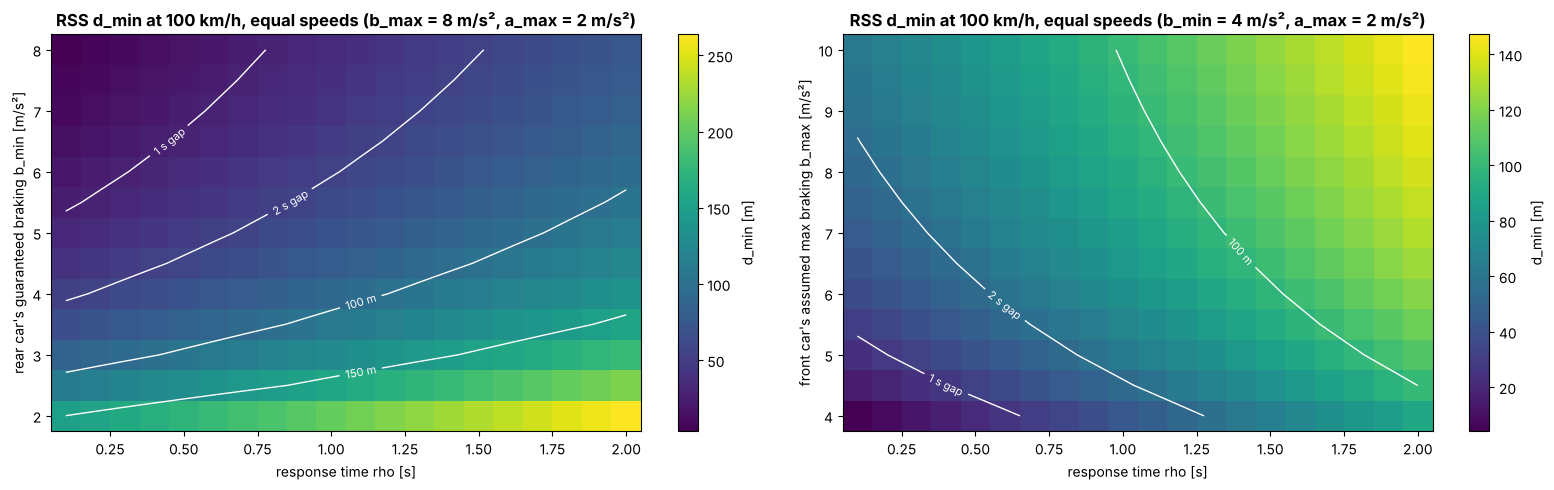

Baseline d_min at 100 km/h: 69.4 m. Change for a small perturbation of one parameter:
  b_min -0.5 m/s²     +14.8 m
  rho +0.1 s           +4.3 m
  b_max +0.5 m/s²      +2.8 m
  a_max +0.5 m/s²      +1.9 m
Text summary: the most sensitive parameter (for these perturbations) is 'b_min -0.5 m/s²'.


In [9]:
v = 100 * KMH
rhos = np.round(np.arange(0.1, 2.01, 0.1), 2)
bmins = np.round(np.arange(2.0, 8.01, 0.5), 2)
bmaxs = np.round(np.arange(4.0, 10.01, 0.5), 2)
H1 = np.array([[rss_safe_longitudinal_distance(v, v, rho=r, b_min_brake=b) for r in rhos] for b in bmins])
H2 = np.array([[rss_safe_longitudinal_distance(v, v, rho=r, b_max_brake=b) for r in rhos] for b in bmaxs])

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, Hm, ys, ylab, fixed in [(axes[0], H1, bmins, "rear car's guaranteed braking b_min [m/s²]", "b_max = 8 m/s²"),
                                (axes[1], H2, bmaxs, "front car's assumed max braking b_max [m/s²]", "b_min = 4 m/s²")]:
    im = ax.imshow(Hm, origin="lower", aspect="auto", cmap="viridis",
                   extent=[rhos[0] - 0.05, rhos[-1] + 0.05, ys[0] - 0.25, ys[-1] + 0.25])
    cs = ax.contour(rhos, ys, Hm, levels=[v * 1.0, v * 2.0, 100, 150], colors="white", linewidths=1)
    ax.clabel(cs, fmt={v * 1.0: "1 s gap", v * 2.0: "2 s gap", 100: "100 m", 150: "150 m"}, fontsize=8)
    ax.set(title=f"RSS d_min at 100 km/h, equal speeds ({fixed}, a_max = 2 m/s²)",
           xlabel="response time rho [s]", ylabel=ylab)
    ax.grid(False)
    plt.colorbar(im, ax=ax, label="d_min [m]")
plt.tight_layout(); plt.show()

base = rss_safe_longitudinal_distance(v, v)
sens = {"rho +0.1 s": rss_safe_longitudinal_distance(v, v, rho=0.6) - base,
        "a_max +0.5 m/s²": rss_safe_longitudinal_distance(v, v, a_max_accel=2.5) - base,
        "b_min -0.5 m/s²": rss_safe_longitudinal_distance(v, v, b_min_brake=3.5) - base,
        "b_max +0.5 m/s²": rss_safe_longitudinal_distance(v, v, b_max_brake=8.5) - base}
print(f"Baseline d_min at 100 km/h: {base:.1f} m. Change for a small perturbation of one parameter:")
for k, dv in sorted(sens.items(), key=lambda kv: -abs(kv[1])):
    print(f"  {k:<18} {dv:+6.1f} m")
print(f"Text summary: the most sensitive parameter (for these perturbations) is '{max(sens, key=lambda k: abs(sens[k]))}'.")

## 6. The safety–usefulness trade-off

The paper's Remark 2 states the tension directly: a larger $b_{\max}$ makes the model *sound* in more situations (fewer cases where the assumption is violated) but induces extremely defensive driving; with $b_{\max} = \infty$ every car ahead must be treated as standing still. We compare three illustrative parameter sets with widely taught human rules of thumb for following distance: the *two-second rule*, the German rule of thumb *"halber Tacho"* (distance in metres equal to half the speed in km/h, i.e. a 1.8 s time gap), and a 1 s time gap often observed in dense traffic. We also translate the required gap into an upper bound on lane throughput, $q = 3600\, v / (d + L)$ vehicles per hour with vehicle length $L = 4.5$ m.

> **Illustrative data:** values below are synthetic, chosen for teaching; they are not measurements.

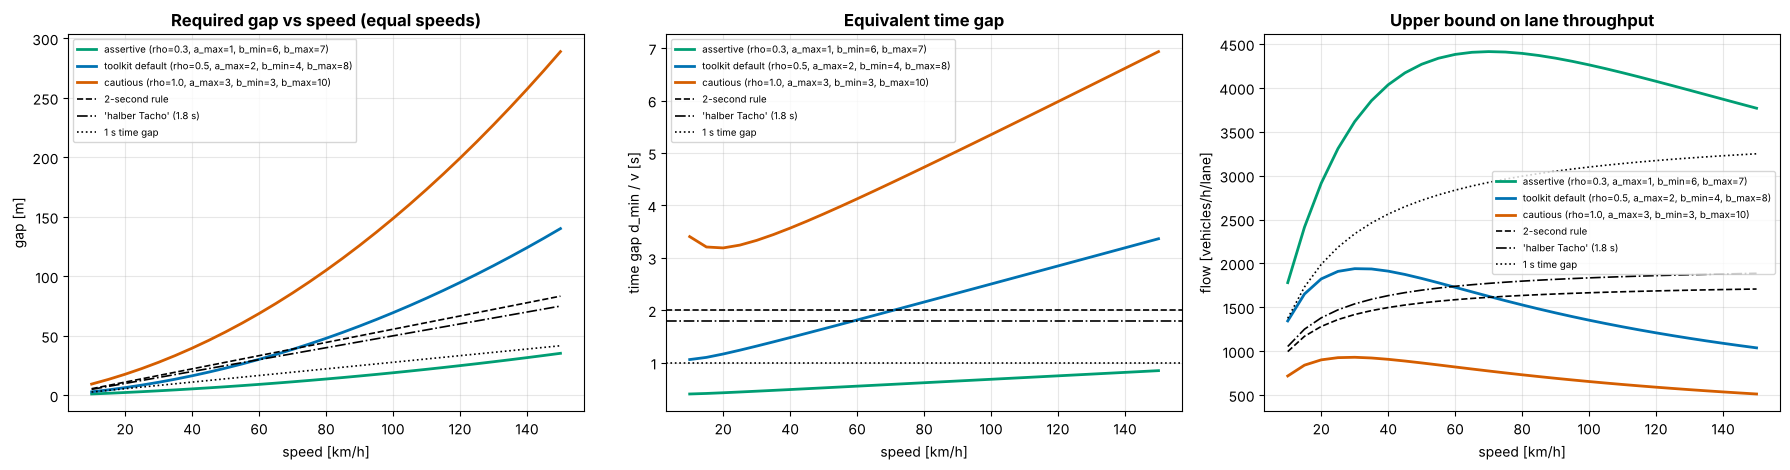

Equivalent RSS time gap [s] at equal speeds:
speed [km/h]      50    100   130
parameter set                    
assertive        0.52  0.68  0.78
cautious         3.84  5.35  6.30
toolkit default  1.65  2.50  3.02

Text summary: with the toolkit defaults the RSS time gap is 1.65 s at 50 km/h and 3.02 s at 130 km/h, i.e. longer than the 2-second rule at motorway speed. The time gap grows with speed because braking distance grows with v², unlike a constant-time-gap rule.


In [10]:
PARAM_SETS = {
    "assertive (rho=0.3, a_max=1, b_min=6, b_max=7)": dict(rho=0.3, a_max_accel=1.0, b_min_brake=6.0, b_max_brake=7.0),
    "toolkit default (rho=0.5, a_max=2, b_min=4, b_max=8)": dict(),
    "cautious (rho=1.0, a_max=3, b_min=3, b_max=10)": dict(rho=1.0, a_max_accel=3.0, b_min_brake=3.0, b_max_brake=10.0),
}
PCOL = [OI["green"], OI["blue"], OI["vermillion"]]
speeds_kmh = np.arange(10, 151, 5)
L_VEH = 4.5
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
rows = []
for (name, p), c in zip(PARAM_SETS.items(), PCOL):
    d = np.array([rss_safe_longitudinal_distance(s * KMH, s * KMH, **p) for s in speeds_kmh])
    axes[0].plot(speeds_kmh, d, color=c, lw=2, label=name)
    axes[1].plot(speeds_kmh, d / (speeds_kmh * KMH), color=c, lw=2, label=name)
    axes[2].plot(speeds_kmh, 3600 * speeds_kmh * KMH / (d + L_VEH), color=c, lw=2, label=name)
    for s in (50, 100, 130):
        rows.append({"parameter set": name.split(" (")[0], "speed [km/h]": s,
                     "d_min [m]": rss_safe_longitudinal_distance(s * KMH, s * KMH, **p),
                     "time gap [s]": rss_safe_longitudinal_distance(s * KMH, s * KMH, **p) / (s * KMH)})
for tg, ls, lab in [(2.0, "--", "2-second rule"), (1.8, "-.", "'halber Tacho' (1.8 s)"), (1.0, ":", "1 s time gap")]:
    axes[0].plot(speeds_kmh, tg * speeds_kmh * KMH, color=OI["black"], ls=ls, lw=1.2, label=lab)
    axes[1].axhline(tg, color=OI["black"], ls=ls, lw=1.2, label=lab)
    axes[2].plot(speeds_kmh, 3600 * speeds_kmh * KMH / (tg * speeds_kmh * KMH + L_VEH), color=OI["black"], ls=ls, lw=1.2,
                 label=lab)
axes[0].set(title="Required gap vs speed (equal speeds)", xlabel="speed [km/h]", ylabel="gap [m]")
axes[1].set(title="Equivalent time gap", xlabel="speed [km/h]", ylabel="time gap d_min / v [s]")
axes[2].set(title="Upper bound on lane throughput", xlabel="speed [km/h]", ylabel="flow [vehicles/h/lane]")
for a in axes: a.legend(fontsize=7)
plt.tight_layout(); plt.show()

tg_df = pd.DataFrame(rows).pivot_table(index="parameter set", columns="speed [km/h]", values="time gap [s]")
print("Equivalent RSS time gap [s] at equal speeds:")
print(tg_df.round(2).to_string())
d_def = tg_df.loc["toolkit default"]
print(f"\nText summary: with the toolkit defaults the RSS time gap is {d_def[50]:.2f} s at 50 km/h and "
      f"{d_def[130]:.2f} s at 130 km/h, i.e. {'longer' if d_def[130] > 2.0 else 'shorter'} than the 2-second rule at "
      f"motorway speed. The time gap grows with speed because braking distance grows with v², "
      f"unlike a constant-time-gap rule.")

Two features stand out. First, unlike human time-gap rules, the RSS gap grows **quadratically** with speed when $b_{\min} < b_{\max}$, because the rear car is assumed to brake less hard than the front car. Second, the parameter set alone moves the envelope from "far more defensive than any human rule of thumb" to "shorter than the 1 s time gap of dense traffic". The parameters therefore carry most of the safety argument, which is why their **justification** (data on real braking behaviour, road friction in the ODD, the vehicle's actual response time) is central and why standardisation bodies have taken up the question of which assumptions are reasonable (Section 8).

## 7. A cut-in scenario: RSS-compliant versus naive control

### 7.1 Scenario and controllers

The ego vehicle drives at 100 km/h. A vehicle in the adjacent lane at 80 km/h, initially $g_0$ metres ahead (bumper to bumper), changes into the ego lane over 3 s (lateral offset from 3.5 m to 0), and once in the lane brakes at $b_{\text{lead}}$ to a standstill. Both ego controllers act through the same 0.3 s actuation delay (less than RSS's $\rho = 0.5$ s) and the same physical limits (+2 / −9 m/s²).

- **Naive controller.** Adaptive cruise control with a 1.0 s time gap and comfort limits (−3.5 m/s²), which considers the other car only once its centre is inside the ego lane. An emergency-braking layer commands −9 m/s² if TTC < 1.5 s.
- **RSS controller.** At every step it evaluates the longitudinal *and* lateral RSS distances. If the situation is dangerous (both unsafe), it applies the longitudinal proper response with exactly $b_{\min} = 4$ m/s², the *minimum* RSS requires. Otherwise it follows the car at $d_{\min} + 5$ m. It reacts as soon as the *lateral* distance becomes unsafe, i.e. before the cut-in vehicle is fully in the lane.

> **Illustrative data:** values below are synthetic, chosen for teaching; they are not measurements.

In [11]:
W_VEH, LANE = 1.8, 3.5              # vehicle width, lane width [m]
RSS_LONG = dict(rho=0.5, a_max_accel=2.0, b_min_brake=4.0, b_max_brake=8.0)
V_SET = 100 * KMH


def naive_controller(o, time_gap=1.0, aeb_ttc=1.5):
    if not o["in_lane"]:
        return float(np.clip(0.5 * (V_SET - o["v_e"]), -3.5, 1.5))
    a = 0.3 * (o["gap"] - (2.0 + time_gap * o["v_e"])) + 0.8 * (o["v_l"] - o["v_e"])
    a = float(np.clip(a, -3.5, 1.5))
    if time_to_collision(o["gap"], o["v_e"], o["v_l"]) < aeb_ttc:
        a = -9.0                                            # emergency braking
    return a


def rss_controller(o, b_min=RSS_LONG["b_min_brake"]):
    if o["lat_danger"] and o["long_danger"]:
        return -b_min                                       # longitudinal proper response (minimum required)
    if o["lat_overlap"] or o["lat_danger"]:
        a = 0.3 * (o["gap"] - (o["dmin"] + 5.0)) + 0.8 * (o["v_l"] - o["v_e"])
        return float(np.clip(a, -3.0, 2.0))
    return float(np.clip(0.5 * (V_SET - o["v_e"]), -3.0, 2.0))


def simulate_cut_in(controller, gap0=40.0, v_e0=100 * KMH, v_l0=80 * KMH, t_ci=1.0, T_lc=3.0, b_lead=7.0,
                    delay=0.3, dt=0.01, T=12.0):
    t_brake = t_ci + T_lc
    n = int(round(T / dt)) + 1
    buf = [0.0] * int(round(delay / dt))                   # actuation delay line
    x_e, v_e, x_l, v_l = 0.0, v_e0, gap0, v_l0
    rec = {k: [] for k in ["t", "gap", "v_e", "v_l", "y", "a_e", "dmin", "dlat", "dlat_min", "danger",
                           "TTC", "THW", "DRAC"]}
    collided, v_impact = False, 0.0
    t_long_danger = t_lat_danger = None
    for k in range(n):
        t = k * dt
        if t < t_ci:
            y, vy = LANE, 0.0
        elif t < t_ci + T_lc:
            ph = math.pi * (t - t_ci) / T_lc
            y, vy = LANE * (1 + math.cos(ph)) / 2, -LANE * math.pi / (2 * T_lc) * math.sin(ph)
        else:
            y, vy = 0.0, 0.0
        a_l = -b_lead if (t >= t_brake and v_l > 0) else 0.0
        gap = x_l - x_e
        lat_gap = max(y - W_VEH, 0.0)                        # cut-in car on the left of the ego car
        dlat_min = rss_safe_lateral_distance(-vy, 0.0)        # its rightward lateral speed is -vy >= 0
        dmin = rss_safe_longitudinal_distance(v_e, v_l, **RSS_LONG)
        lat_danger, long_danger = lat_gap < dlat_min, gap < dmin
        if long_danger and t_long_danger is None: t_long_danger = t
        if lat_danger and t_lat_danger is None: t_lat_danger = t
        overlap = y < W_VEH
        o = dict(gap=gap, v_e=v_e, v_l=v_l, dmin=dmin, in_lane=y < LANE / 2, lat_overlap=overlap,
                 lat_danger=lat_danger, long_danger=long_danger)
        buf.append(controller(o))
        a_e = float(np.clip(buf.pop(0), -9.0, 2.0))
        if v_e <= 0 and a_e < 0:
            a_e = 0.0
        for key, val in [("t", t), ("gap", gap), ("v_e", v_e), ("v_l", v_l), ("y", y), ("a_e", a_e), ("dmin", dmin),
                         ("dlat", lat_gap), ("dlat_min", dlat_min), ("danger", lat_danger and long_danger),
                         ("TTC", time_to_collision(gap, v_e, v_l) if overlap else np.inf),
                         ("THW", time_headway(gap, v_e) if overlap else np.inf),
                         ("DRAC", drac(gap, v_e, v_l) if overlap else 0.0)]:
            rec[key].append(val)
        if overlap and gap <= 0:
            collided, v_impact = True, v_e - v_l
            break
        x_e += v_e * dt + 0.5 * a_e * dt * dt; v_e = max(v_e + a_e * dt, 0.0)
        x_l += v_l * dt + 0.5 * a_l * dt * dt; v_l = max(v_l + a_l * dt, 0.0)
    rec = pd.DataFrame(rec)
    info = dict(collided=collided, v_impact=v_impact, t_long_danger=t_long_danger, t_lat_danger=t_lat_danger)
    return rec, info


CONTROLLERS = {"naive (ACC 1.0 s + AEB)": naive_controller, "RSS proper response": rss_controller}
CCOL = {"naive (ACC 1.0 s + AEB)": OI["vermillion"], "RSS proper response": OI["blue"]}
runs = {name: simulate_cut_in(c) for name, c in CONTROLLERS.items()}
for name, (rec, info) in runs.items():
    print(f"{name:<26} collision: {info['collided']}"
          + (f" (impact speed {info['v_impact']:.1f} m/s = {info['v_impact'] / KMH:.0f} km/h)" if info["collided"] else ""))

naive (ACC 1.0 s + AEB)    collision: True (impact speed 5.7 m/s = 20 km/h)
RSS proper response        collision: False


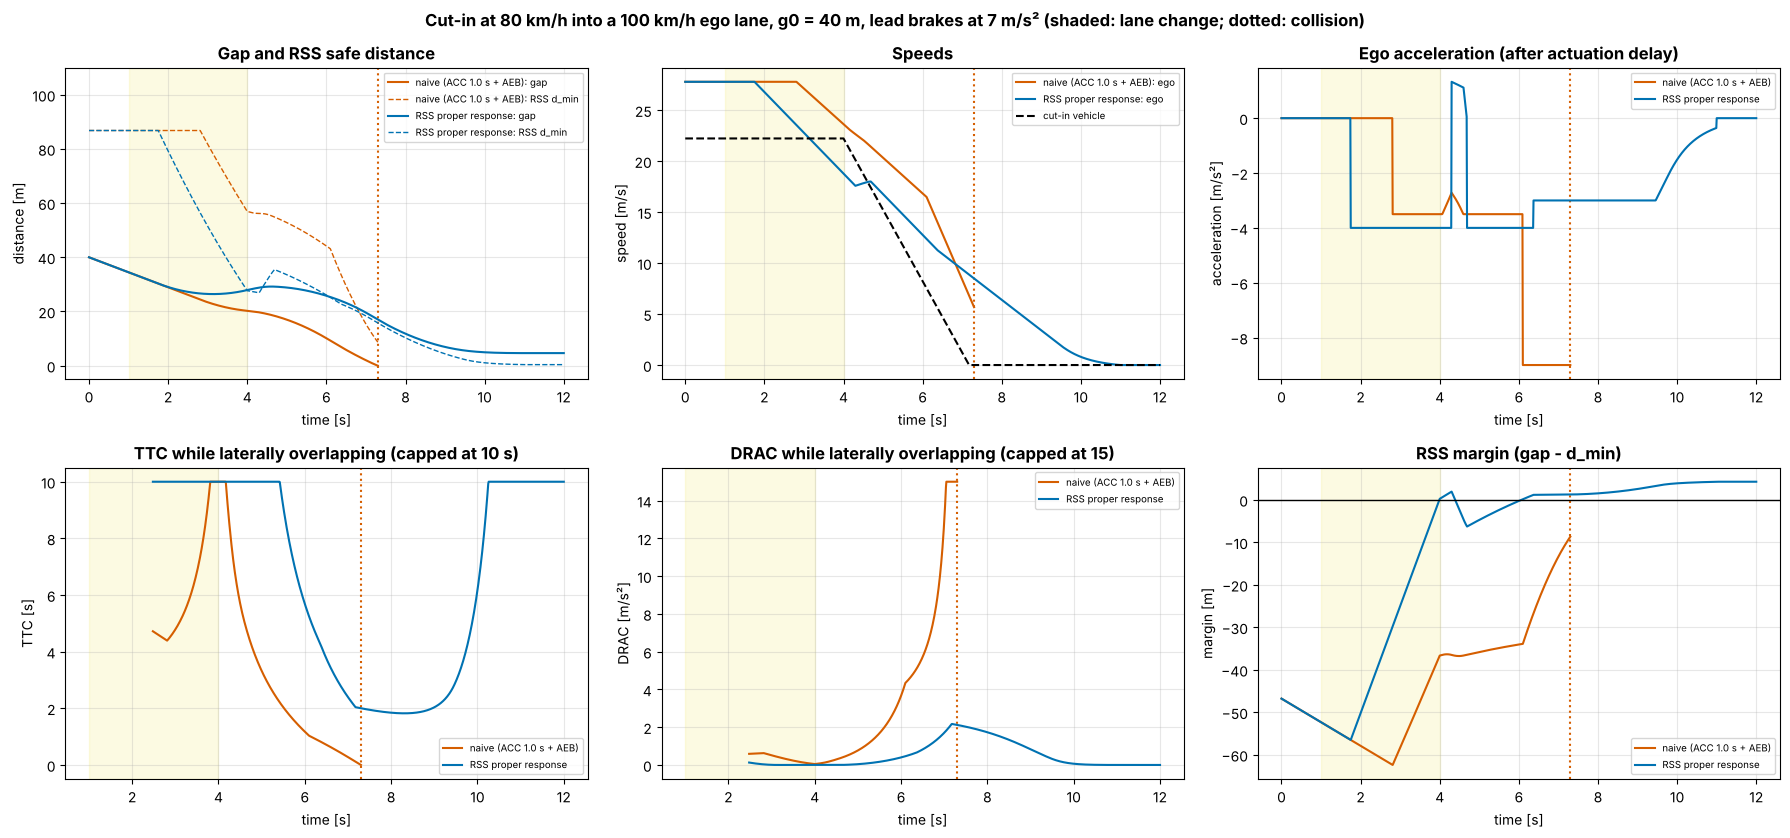

                         collision  impact speed [km/h]  first braking [s]  min TTC [s]  min THW [s]  max DRAC [m/s2]  time RSS-unsafe [s]  peak decel [m/s2]
controller                                                                                                                                                   
naive (ACC 1.0 s + AEB)       True                20.44               2.81         0.01         0.01           395.17                 7.31                9.0
RSS proper response          False                 0.00               1.75         1.82         1.10             2.17                 5.68                4.0

Text summary: the RSS controller starts braking at t = 1.75 s, 1.06 s earlier than the naive controller, because the lateral distance becomes unsafe before the cut-in vehicle enters the lane. Outcome: naive collides at 20 km/h; RSS avoids the collision with a peak deceleration of 4.0 m/s².


In [12]:
fig, axes = plt.subplots(2, 3, figsize=(18, 8.5))
for name, (rec, info) in runs.items():
    c = CCOL[name]
    ov = rec[rec.y < W_VEH]
    axes[0, 0].plot(rec.t, rec.gap, color=c, label=f"{name}: gap")
    axes[0, 0].plot(rec.t, rec.dmin, color=c, ls="--", lw=1, label=f"{name}: RSS d_min")
    axes[0, 1].plot(rec.t, rec.v_e, color=c, label=f"{name}: ego")
    axes[0, 2].plot(rec.t, rec.a_e, color=c, label=name)
    axes[1, 0].plot(ov.t, np.minimum(ov.TTC, 10), color=c, label=name)
    axes[1, 1].plot(ov.t, np.minimum(ov.DRAC, 15), color=c, label=name)
    axes[1, 2].plot(rec.t, rec.gap - rec.dmin, color=c, label=name)
    if info["collided"]:
        for ax in axes.ravel():
            ax.axvline(rec.t.iloc[-1], color=c, ls=":", lw=1.5)
rec0 = runs["RSS proper response"][0]
axes[0, 1].plot(rec0.t, rec0.v_l, color=OI["black"], ls="--", label="cut-in vehicle")
axes[0, 0].set(title="Gap and RSS safe distance", xlabel="time [s]", ylabel="distance [m]", ylim=(-5, 110))
axes[0, 1].set(title="Speeds", xlabel="time [s]", ylabel="speed [m/s]")
axes[0, 2].set(title="Ego acceleration (after actuation delay)", xlabel="time [s]", ylabel="acceleration [m/s²]")
axes[1, 0].set(title="TTC while laterally overlapping (capped at 10 s)", xlabel="time [s]", ylabel="TTC [s]")
axes[1, 1].set(title="DRAC while laterally overlapping (capped at 15)", xlabel="time [s]", ylabel="DRAC [m/s²]")
axes[1, 2].axhline(0, color=OI["black"], lw=1)
axes[1, 2].set(title="RSS margin (gap - d_min)", xlabel="time [s]", ylabel="margin [m]")
for ax in axes.ravel():
    ax.axvspan(1.0, 4.0, color=OI["yellow"], alpha=0.15)
    ax.legend(fontsize=7)
plt.suptitle("Cut-in at 80 km/h into a 100 km/h ego lane, g0 = 40 m, lead brakes at 7 m/s² (shaded: lane change; "
             "dotted: collision)", fontweight="bold")
plt.tight_layout(); plt.show()

summ = []
for name, (rec, info) in runs.items():
    ov = rec[(rec.y < W_VEH) & (rec.gap > 0)]
    first_brake = rec.loc[rec.a_e < -0.5, "t"].min()
    summ.append({"controller": name, "collision": info["collided"], "impact speed [km/h]": info["v_impact"] / KMH,
                 "first braking [s]": first_brake, "min TTC [s]": ov.TTC.min(), "min THW [s]": ov.THW.min(),
                 "max DRAC [m/s2]": ov.DRAC.max(), "time RSS-unsafe [s]": (rec.gap < rec.dmin).sum() * 0.01,
                 "peak decel [m/s2]": -rec.a_e.min()})
summ = pd.DataFrame(summ).set_index("controller")
print(summ.round(2).to_string())
n, r = summ.loc["naive (ACC 1.0 s + AEB)"], summ.loc["RSS proper response"]
print(f"\nText summary: the RSS controller starts braking at t = {r['first braking [s]']:.2f} s, "
      f"{n['first braking [s]'] - r['first braking [s]']:.2f} s earlier than the naive controller, because the lateral "
      f"distance becomes unsafe before the cut-in vehicle enters the lane. Outcome: naive "
      f"{'collides at %.0f km/h' % n['impact speed [km/h]'] if n['collision'] else 'avoids the collision'}; RSS "
      f"{'collides at %.0f km/h' % r['impact speed [km/h]'] if r['collision'] else 'avoids the collision'} "
      f"with a peak deceleration of {r['peak decel [m/s2]']:.1f} m/s².")

Note what the metrics show over time. While the cut-in vehicle is still in its own lane, TTC, THW and DRAC are *undefined* for the ego lane, so a controller (or an evaluation) based on them alone starts late. The longitudinal RSS margin to the adjacent-lane car is negative throughout, but the situation becomes *dangerous* only when the lateral distance is also unsafe, shortly after the lane change begins; that combined check is exactly the information an envelope adds. Note also that the RSS controller is in the RSS-unsafe region for a long time without any violation of *its own* proper response: the danger was created by the other vehicle.

### 7.2 Outcome map over cut-in gap and lead braking

We now sweep the initial gap $g_0$ and the cut-in vehicle's braking $b_{\text{lead}}$. Values $b_{\text{lead}} > b_{\max} = 8$ m/s² violate RSS's assumption about the front car.

198 simulations in 3.1 s


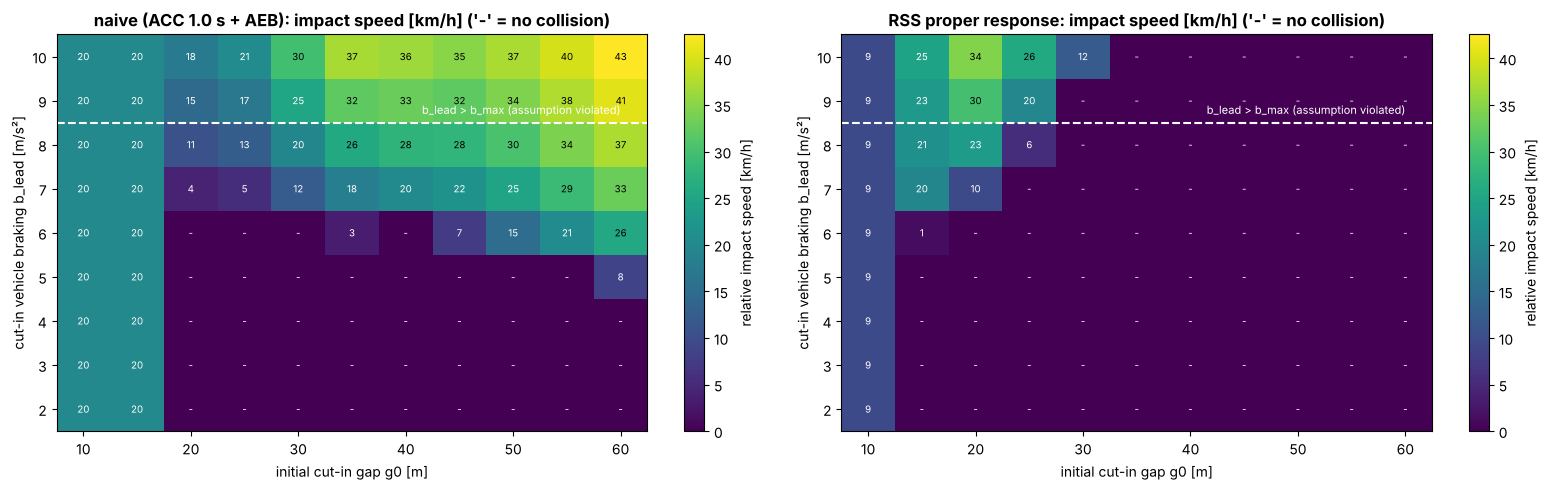

Collisions: naive 60/99, RSS 22/99.
RSS collisions with b_lead <= b_max: 13; in 13 of them the longitudinal distance was already unsafe when the lateral danger began, i.e. the dangerous situation was created by the cut-in vehicle's lateral manoeuvre (its lateral proper response was violated).
RSS collisions with b_lead > b_max: 9.
Cells where RSS collides but the naive controller does not: 0.


In [13]:
g_grid = np.arange(10, 61, 5)
b_grid = np.arange(2, 11, 1)
t_sweep = time.time()
impact = {name: np.zeros((len(b_grid), len(g_grid))) for name in CONTROLLERS}
cause = []
for i, bl in enumerate(b_grid):
    for j, g0 in enumerate(g_grid):
        for name, c in CONTROLLERS.items():
            rec, info = simulate_cut_in(c, gap0=float(g0), b_lead=float(bl))
            impact[name][i, j] = info["v_impact"] / KMH if info["collided"] else 0.0
            if name == "RSS proper response" and info["collided"]:
                cause.append({"g0": g0, "b_lead": bl, "within b_max": bl <= RSS_LONG["b_max_brake"],
                              "long. unsafe before lateral danger": info["t_long_danger"] <= info["t_lat_danger"]})
print(f"{len(b_grid) * len(g_grid) * len(CONTROLLERS)} simulations in {time.time() - t_sweep:.1f} s")

vmax = max(m.max() for m in impact.values())
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, (name, M) in zip(axes, impact.items()):
    im = ax.imshow(M, origin="lower", aspect="auto", cmap="viridis", vmin=0, vmax=vmax,
                   extent=[g_grid[0] - 2.5, g_grid[-1] + 2.5, b_grid[0] - 0.5, b_grid[-1] + 0.5])
    ax.axhline(RSS_LONG["b_max_brake"] + 0.5, color="white", ls="--", lw=1.5)
    ax.text(g_grid[-1], RSS_LONG["b_max_brake"] + 0.7, "b_lead > b_max (assumption violated)", color="white",
            ha="right", fontsize=8)
    for (a, b), val in np.ndenumerate(M):
        ax.text(g_grid[b], b_grid[a], "-" if val == 0 else f"{val:.0f}", ha="center", va="center", fontsize=7,
                color="black" if val > 0.6 * vmax else "white")
    ax.set(title=f"{name}: impact speed [km/h] ('-' = no collision)", xlabel="initial cut-in gap g0 [m]",
           ylabel="cut-in vehicle braking b_lead [m/s²]")
    ax.grid(False)
    plt.colorbar(im, ax=ax, label="relative impact speed [km/h]")
plt.tight_layout(); plt.show()

cause = pd.DataFrame(cause)
n_cells = impact["naive (ACC 1.0 s + AEB)"].size
n_naive = int((impact["naive (ACC 1.0 s + AEB)"] > 0).sum()); n_rss = int((impact["RSS proper response"] > 0).sum())
print(f"Collisions: naive {n_naive}/{n_cells}, RSS {n_rss}/{n_cells}.")
if len(cause):
    inside = cause[cause["within b_max"]]
    print(f"RSS collisions with b_lead <= b_max: {len(inside)}; in "
          f"{int(inside['long. unsafe before lateral danger'].sum()) if len(inside) else 0} of them the longitudinal "
          f"distance was already unsafe when the lateral danger began, i.e. the dangerous situation was created by the "
          f"cut-in vehicle's lateral manoeuvre (its lateral proper response was violated).")
    print(f"RSS collisions with b_lead > b_max: {int((~cause['within b_max']).sum())}.")
both = int(((impact["naive (ACC 1.0 s + AEB)"] == 0) & (impact["RSS proper response"] > 0)).sum())
print(f"Cells where RSS collides but the naive controller does not: {both}.")

**Reading the outcome map.**

- Where the naive controller collides at larger $g_0$, it has simply waited too long: it ignored the vehicle until it was in the lane and then relied on a comfort-limited controller plus a TTC trigger.
- The RSS controller can still collide, mainly where the cut-in happens at a short gap and the lead brakes hard. In these cells the cut-in vehicle created the dangerous situation itself: RSS assigns **responsibility** to it, not to the ego vehicle. RSS guarantees that the ego vehicle does not *cause* collisions under its assumptions; it does not guarantee that the ego vehicle is never hit or never runs into a reckless cut-in.
- Our RSS controller brakes with exactly $b_{\min}$. RSS allows (and rule 5 asks for) braking harder when that avoids a collision without causing another one (Section 3.6, "compensating for improper behavior of others"). Exercise 3 asks you to add this.
- At $g_0 \le 15$ m both controllers collide whatever the lead does: the cut-in vehicle moves into the ego vehicle's lane where there is no room. No longitudinal controller can prevent this; only a lateral evasive manoeuvre or the other driver could.
- The envelope is a *specification* of acceptable behaviour, not a substitute for good emergency manoeuvres; the last printed line checks whether minimum-compliance RSS is ever worse than the naive controller on this grid.

## 8. Safety envelopes in standards and safety arguments

| Document | Role of criticality metrics / envelopes |
|---|---|
| **ISO 21448:2022** (SOTIF) | Criticality metrics help define acceptance criteria and validation targets, evaluate known hazardous scenarios and search for unknown ones; an envelope's parameters are *assumptions* whose violation is itself a potential triggering condition (e.g. a lead vehicle braking harder than $b_{\max}$, a low-friction road making $b_{\min}$ unattainable). |
| **IEEE 2846-2022** *IEEE Standard for Assumptions in Safety-Related Models for Automated Driving Systems* (published April 2022) | Defines, for a set of scenarios, a *minimum set of assumptions about reasonably foreseeable behaviour of other road users* that should be considered when developing safety-related models such as RSS, based on kinematic properties; it also describes a method to check whether a model accounts for them. Its scope excludes perception and prediction errors, and it does not claim to guarantee overall system safety (IEEE SA, as of October 2026). |
| **UL 4600** (3rd ed., 2023) *Standard for Evaluation of Autonomous Products* | A goal-based safety-case standard. An envelope can support claims such as "the vehicle does not initiate collisions within the ODD", but the safety case must also argue that the *assumptions* are valid, that the inputs (perceived states) are accurate enough, and that violations are detected and handled. |
| **ISO 34502:2022** | A scenario-based safety evaluation framework in which criticality metrics are used to assess test scenarios. |
| **UN Regulation No. 157** (ALKS) | Annex 3 provides human-driver performance models as a benchmark for whether collisions in cut-in, cut-out and deceleration scenarios are preventable; Olleja et al. (2025) examine how competent and careful these models actually are. |

In a safety argument (see [Module 08, Notebook 04](../08_Standards_Regulation_and_Safety_Case/04_safety_case_gsn.ipynb)), an envelope typically appears as a **strategy** ("argue over compliance with a formal behavioural model") whose sub-claims are: the model is correctly implemented (verification, e.g. the unit tests and worst-case simulation above); its parameters are valid for the ODD (data and IEEE 2846-type assumptions); the inputs are trustworthy (perception performance, including the tracking consistency of [Module 01, Notebook 07](../01_Perception/07_multi_object_tracking.ipynb)); and residual cases outside the assumptions are acceptable (SOTIF residual-risk evaluation).

## 9. Limitations

1. **Perceived, not true, states.** RSS is evaluated on *estimated* speeds and distances. A one-sided treatment of uncertainty (e.g. using $v_f - 2\sigma_v$ for the front car) costs distance, as the cell below quantifies. Koopman, Osyk and Weast (2019) discuss how variability and uncertainty complicate proofs of safety based on RSS.
2. **Assumptions about others.** The guarantee holds only if other agents stay within $(a_{\max}, b_{\max})$ and respond properly. Real drivers occasionally brake harder or cut in recklessly; the envelope then shifts *responsibility*, not physical outcomes.
3. **ODD-dependent parameters.** $b_{\min}$ must be achievable on the actual road surface; the paper itself notes that parameters can be set differently for road conditions (Remark 2). Using dry-road values on ice invalidates the envelope.
4. **Occlusions and unknown agents.** The definitions require assumptions about agents that cannot be seen (Section 3.9 of the paper); the envelope cannot protect against objects the perception system never reports.
5. **Responsibility is not safety.** A system can be "never at fault" and still be involved in avoidable crashes; acceptance criteria in SOTIF and UL 4600 concern the overall risk, not only blame.
6. **Usefulness.** Conservative parameters reduce throughput and can create new risks (e.g. provoking cut-ins or rear-end conflicts by unexpectedly large gaps).

Related approaches include online verification with reachable sets (Pek et al., 2020), which checks at runtime that a fail-safe trajectory exists under bounded behaviour of others.

In [14]:
v_r = v_f = 100 * KMH
d_true = rss_safe_longitudinal_distance(v_r, v_f)
rows = []
for sigma_v in (0.0, 0.5, 1.0, 2.0):
    for latency in (0.0, 0.1, 0.3):
        # conservative use of the estimate: rear speed + 2 sigma, front speed - 2 sigma, response time + latency
        d_cons = rss_safe_longitudinal_distance(v_r + 2 * sigma_v, max(v_f - 2 * sigma_v, 0.0), rho=0.5 + latency)
        rows.append({"speed sigma [m/s]": sigma_v, "extra latency [s]": latency, "d_min [m]": d_cons,
                     "increase vs exact state [m]": d_cons - d_true})
unc = pd.DataFrame(rows).pivot_table(index="speed sigma [m/s]", columns="extra latency [s]",
                                     values="increase vs exact state [m]")
print(f"Exact-state d_min at 100 km/h: {d_true:.1f} m. Additional distance [m] when uncertainty is handled conservatively:")
print(unc.round(1).to_string())
print(f"\nText summary: a speed uncertainty of 1 m/s (2-sigma bound on both cars) and 0.1 s extra latency add "
      f"{unc.loc[1.0, 0.1]:.1f} m ({unc.loc[1.0, 0.1] / d_true:.0%}) to the required gap.")

Exact-state d_min at 100 km/h: 69.4 m. Additional distance [m] when uncertainty is handled conservatively:
extra latency [s]   0.0   0.1   0.3
speed sigma [m/s]                  
0.0                 0.0   4.3  13.1
0.5                11.2  15.7  24.8
1.0                22.6  27.2  36.6
2.0                45.7  50.6  60.6

Text summary: a speed uncertainty of 1 m/s (2-sigma bound on both cars) and 0.1 s extra latency add 27.2 m (39%) to the required gap.


## 10. Exercises

**Exercise 1 (formula).** Show that for equal speeds $v_r = v_f = v$ and $b_{\min} = b_{\max} = b$, the RSS distance reduces to $v\rho + \tfrac{1}{2}a_{\max}\rho^2 + \frac{(v+\rho a_{\max})^2 - v^2}{2b}$, which grows only *linearly* in $v$. Check numerically with `rss_safe_longitudinal_distance`.

<details><summary>Answer</summary>

Substituting gives $v\rho + \tfrac12 a\rho^2 + \frac{2v\rho a + \rho^2a^2}{2b}$, which is linear in $v$ with slope $\rho(1 + a/b)$. For $\rho = 0.5$, $a = 2$, $b = 8$: slope $0.625$ s, so the time gap tends to 0.625 s at high speed. Numerically: `rss_safe_longitudinal_distance(v, v, b_min_brake=8, b_max_brake=8) / v` approaches 0.625 for large `v`. The quadratic growth in Section 6 is entirely due to $b_{\min} < b_{\max}$.
</details>

**Exercise 2 (metric failure).** Construct a situation in which TTC > 5 s but the required deceleration exceeds 6 m/s². What property of the situation makes TTC misleading?

<details><summary>Answer</summary>

For example gap 20 m, both at 25 m/s, lead braking at 9 m/s²: TTC is infinite (no closing speed yet), but `required_deceleration(20, 25, 25, 9)` is above 6 m/s². TTC extrapolates the *current* speeds, so it ignores the lead's deceleration; any metric must be read together with its prediction model.
</details>

**Exercise 3 (rule 5).** Modify `rss_controller` so that, when dangerous, it brakes with $\max(b_{\min}, a_{\text{req}})$, where $a_{\text{req}}$ is `required_deceleration(gap, v_e, v_l, b_lead_estimate)` limited to 9 m/s². Re-run the outcome map. Which cells change, and is the controller still RSS-compliant?

<details><summary>Answer</summary>

Collisions at short gaps with moderate lead braking largely disappear, because the controller now uses the available braking capacity. It remains RSS-compliant: proper response requires braking by *at least* $b_{\min}$, and rule 5 asks the vehicle to avoid accidents it can avoid without causing another one (consider the following traffic before braking hard). The remaining collisions are physically unavoidable with 9 m/s² and the actuation delay. Pass `b_lead` into the observation dictionary `o` to make the estimate available.
</details>

**Exercise 4 (parameters and the ODD).** A shuttle operates at ≤ 30 km/h in a pedestrian zone. Propose RSS parameters, justify each from the ODD, and compute $d_{\min}$ at 30 km/h behind a bicycle at 15 km/h.

<details><summary>Answer (one possible answer)</summary>

$\rho = 0.5$ s (measured actuation and perception latency plus margin), $a_{\max} = 1$ m/s² (shuttle's limited acceleration), $b_{\min} = 3$ m/s² (comfortable for standing passengers and achievable on wet paving), $b_{\max} = 8$ m/s² for a bicycle (strong braking or a fall). Then `rss_safe_longitudinal_distance(30/3.6, 15/3.6, 0.5, 1, 3, 8)` ≈ 17 m. The justification must cite data on braking capability and friction in the ODD, and the safety case must cover passengers' fall risk under the proper response.
</details>

## Key takeaways

- Surrogate safety metrics (TTC, THW, DRAC, required deceleration, PET) make criticality measurable in every encounter, but each embeds a **prediction model**; TTC is infinite whenever the vehicles are not closing, and longitudinal metrics are blind to lateral conflicts.
- RSS turns "keep a safe distance" into a **derivable, testable formula** from explicit worst-case assumptions: $d_{\min} = [v_r\rho + \tfrac12 a_{\max}\rho^2 + (v_r+\rho a_{\max})^2/2b_{\min} - v_f^2/2b_{\max}]_+$.
- A situation is dangerous only if it is unsafe both longitudinally and laterally; the **proper response** and **responsibility** follow from the danger threshold time.
- The parameters carry the safety argument: small changes in $\rho$ or $b_{\min}$ change the required gap by tens of metres at motorway speed, which is the **safety–usefulness trade-off**.
- In a cut-in, an envelope that reasons laterally reacts earlier than a lane-based ACC; but a responsibility model does not prevent collisions created by others.
- In **ISO 21448**, **IEEE 2846-2022** and **UL 4600** arguments, the envelope is one strategy; its assumptions, its inputs (perception) and its violations must all be argued.

## Self-assessment

1. Why is TTC infinite in a tailgating situation at equal speeds, and which metric does capture that situation?
2. State the worst-case assumptions behind the RSS longitudinal safe distance and derive the formula.
3. Why does the RSS gap grow quadratically with speed when $b_{\min} < b_{\max}$?
4. When is a situation "dangerous" in RSS, and which proper response applies when two cars driving side by side approach each other laterally?
5. What does RSS guarantee, and what does it *not* guarantee?
6. Name two ways in which perception uncertainty enters the RSS check, and how they affect the required distance.
7. How would you use IEEE 2846-2022 and UL 4600 when arguing that an RSS-based monitor is adequate for an ODD?

<details><summary>Answers</summary>

1. TTC divides the gap by the closing speed, which is zero. THW (gap/speed) and the RSS margin capture it, as does the required deceleration once the lead starts braking.
2. The front car brakes at up to $b_{\max}$ immediately; the rear car accelerates at up to $a_{\max}$ during $\rho$, then brakes at only $b_{\min}$. With $b_{\min} \le b_{\max}$ the gap is smallest at standstill; requiring a non-negative gap there gives the formula of Section 4.1.
3. The rear car's braking distance $\propto v^2/2b_{\min}$ exceeds the front car's $v^2/2b_{\max}$ by $v^2(1/b_{\min} - 1/b_{\max})/2$, which is quadratic in $v$.
4. When it is unsafe both longitudinally and laterally (Definition 9). Side by side, the longitudinal distance is already unsafe, so the danger threshold is the lateral one and the lateral proper response applies (Definition 10): both cars must brake laterally.
5. If all agents respond properly, no collisions occur, and an agent that respects its proper response is never responsible for a collision (without occlusions). It does not guarantee the absence of collisions caused by others, nor safety if the parameter assumptions or the perceived states are wrong.
6. Errors in estimated speeds (and distances) and latency of the perception/actuation chain. Conservative handling increases the rear-speed and response-time terms and decreases the front-speed term, all of which enlarge $d_{\min}$ (Section 9).
7. IEEE 2846-2022 provides a minimum set of assumptions about other road users' reasonably foreseeable behaviour against which the model's parameters can be checked; UL 4600 requires a safety case that also covers the validity of these assumptions in the ODD, the adequacy of the inputs, and the handling of violations.
</details>

## References

- Allen, B. L., Shin, B. T., Cooper, P. J. (1978). Analysis of traffic conflicts and collisions. *Transportation Research Record*, 667, 67–74. https://trid.trb.org/view/85806
- Hayward, J. C. (1972). Near-miss determination through use of a scale of danger. *Highway Research Record*, 384, 24–34. https://trid.trb.org/view/115323
- IEEE 2846-2022. *IEEE Standard for Assumptions in Safety-Related Models for Automated Driving Systems*. IEEE Standards Association. https://standards.ieee.org/ieee/2846/10831/
- ISO 21448:2022. *Road vehicles — Safety of the intended functionality*. International Organization for Standardization.
- ISO 34502:2022. *Road vehicles — Test scenarios for automated driving systems — Scenario based safety evaluation framework*. International Organization for Standardization.
- Koopman, P., Osyk, B., Weast, J. (2019). Autonomous vehicles meet the physical world: RSS, variability, uncertainty, and proving safety. *Computer Safety, Reliability, and Security (SAFECOMP 2019)*, LNCS, 245–253. https://doi.org/10.1007/978-3-030-26601-1_17
- Mahmud, S. M. S., Ferreira, L., Hoque, M. S., Tavassoli, A. (2017). Application of proximal surrogate indicators for safety evaluation: a review of recent developments and research needs. *IATSS Research*, 41(4), 153–163. https://doi.org/10.1016/j.iatssr.2017.02.001
- Olleja, P., Markkula, G., Bärgman, J. (2025). Validation of human benchmark models for automated driving system approval: how competent and careful are they really? *Accident Analysis & Prevention*, 213, 107922. https://doi.org/10.1016/j.aap.2025.107922
- Pek, C., Manzinger, S., Koschi, M., Althoff, M. (2020). Using online verification to prevent autonomous vehicles from causing accidents. *Nature Machine Intelligence*, 2, 518–528. https://doi.org/10.1038/s42256-020-0225-y
- Shalev-Shwartz, S., Shammah, S., Shashua, A. (2017). On a formal model of safe and scalable self-driving cars. arXiv:1708.06374 (v6, 2018). https://arxiv.org/abs/1708.06374
- UL 4600 (3rd ed., 2023). *Standard for Evaluation of Autonomous Products*. UL Standards & Engagement. https://ulse.org/ul-standards-engagement/autonomous-vehicle-technology/autonomous-trucking-incorporated-third
- UN Regulation No. 157 — Uniform provisions concerning the approval of vehicles with regard to Automated Lane Keeping Systems. As published in the Official Journal of the EU, L 82, 2021. https://eur-lex.europa.eu/eli/reg/2021/389/oj/eng
- Westhofen, L., Neurohr, C., Koopmann, T., Butz, M., Schütt, B., Utesch, F., Neurohr, B., Gutenkunst, C., Böde, E. (2023). Criticality metrics for automated driving: a review and suitability analysis of the state of the art. *Archives of Computational Methods in Engineering*, 30, 1–35. https://doi.org/10.1007/s11831-022-09788-7

**Related work by the author:** Patel, M., Jung, R., Khatun, M. (2025). A systematic literature review on safety of the intended functionality for automated driving systems. *SAE Technical Paper* 2025-01-5030. https://doi.org/10.4271/2025-01-5030 · Patel, M., Khatun, M., Jung, R., Glaß, M. (2021). Simulation-based analysis of highway trajectory planning using high-order polynomial for highly automated driving function. *ICECCME 2021*. https://doi.org/10.1109/ICECCME52200.2021.9591044

---
**Navigation:** ← [04 Simulation-based validation](04_simulation_based_validation.ipynb) · [Module index](README.md) · [Next module: Cybersecurity (ISO/SAE 21434)](../05_Cybersecurity_ISO21434/README.md) →